# Machine Learning - Trip Duration Prediction

## Business Problem

The objective of this project is to predict taxi trip duration based on trip characteristics and temporal features.

Accurate trip duration prediction can help:

- Improve customer experience
- Optimize transportation planning
- Support traffic management decisions

## Target Variable

trip_duration

In [1]:
import pandas as pd
import numpy as np 

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression 

from sklearn.ensemble import RandomForestClassifier 

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv(
    '../data/processed/NYC_cleaned.csv'

)

df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_year,pickup_month,pickup_day,pickup_hour,pickup_weekday
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,2016,3,14,17,Monday
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,2016,6,12,0,Sunday
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,2016,1,19,11,Tuesday
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,2016,4,6,19,Wednesday
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,2016,3,26,13,Saturday


In [3]:
features = [
    "vendor_id",
    "passenger_count",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "pickup_hour",
    "pickup_month"
]

In [4]:
target = "trip_duration"

In [5]:
X = df[features]

y = df[target]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [7]:
print(X_train.shape)
print(X_test.shape)

(1158204, 8)
(289551, 8)


In [8]:
lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [9]:
lr_predictions = lr.predict(
    X_test
)

In [10]:
lr_mae = mean_absolute_error(
    y_test,
    lr_predictions
)

lr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lr_predictions
    )
)

lr_r2 = r2_score(
    y_test,
    lr_predictions
)


print(f'Mean Absolute Error: {lr_mae:.2f} seconds' )

print(f'Root Mean Square Error: {lr_rmse:.2f} seconds' )

print(f'R-squared: {lr_r2:.2f}' )


Mean Absolute Error: 414.57 seconds
Root Mean Square Error: 573.71 seconds
R-squared: 0.23


# Linear Regression Results

## Model Performance

- Mean Absolute Error (MAE): 414.57 seconds
- Root Mean Square Error (RMSE): 573.71 seconds
- R² Score: 0.23

## Interpretation

The baseline linear regression model explains approximately 23% of the variance in trip duration.

While prediction accuracy remains limited, the model establishes a useful benchmark for comparison with more advanced machine learning algorithms.

In [11]:
from sklearn.ensemble import RandomForestRegressor


In [12]:
rf = RandomForestRegressor(
    n_estimators=20,
    max_depth=15,
    min_samples_leaf=10,
    max_samples=0.5,
    random_state=42,
    n_jobs=1
)

rf.fit(
    X_train,
    y_train
)

,n_estimators,20
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [13]:
rf_predictions = rf.predict(X_test)

In [14]:
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)


print(f'Mean Absolute Error: {rf_mae:.2f} seconds')
print(f'Root Mean Square Error: {rf_rmse:.2f} seconds')
print(f'R-squared: {rf_r2:.2f}')

Mean Absolute Error: 249.35 seconds
Root Mean Square Error: 355.63 seconds
R-squared: 0.70


# Random Forest Results

## Model Performance

- Mean Absolute Error (MAE): 249.35 seconds
- Root Mean Square Error (RMSE): 355.63 seconds
- R² Score: 0.70

## Interpretation

The Random Forest model significantly outperformed the baseline linear regression model.

The model reduced prediction errors and explained approximately 70% of the variance in trip duration.

These results suggest that trip duration is influenced by complex non-linear relationships that are better captured by ensemble tree-based methods.

## Business Value

More accurate trip duration predictions can improve:

- Customer experience
- Travel time estimation
- Transportation planning
- Operational efficiency

In [15]:
from xgboost import XGBRegressor 

In [16]:
xgb = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=1
)

In [17]:
xgb.fit(
    X_train,
    y_train
)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [18]:
xgb_predictions = xgb.predict(X_test)

In [19]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_predictions
)


xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_predictions
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_predictions
)

print(f'Mean Absolute Error :{xgb_mae:.2f} seconds')
print(f'Root Mean Square Error: {xgb_rmse:.2f} seconds')
print(f'R-squared: {xgb_r2:.2f}')

Mean Absolute Error :232.29 seconds
Root Mean Square Error: 341.45 seconds
R-squared: 0.73


# XGBoost Results

## Model Performance

- Mean Absolute Error (MAE): 232.29 seconds
- Root Mean Square Error (RMSE): 341.45 seconds
- R² Score: 0.73

## Interpretation

XGBoost achieved the best predictive performance among all evaluated models.

The model reduced prediction errors and explained approximately 73% of the variance in trip duration.

Compared to Linear Regression and Random Forest, XGBoost provided the most accurate travel time predictions.

## Business Value

Accurate trip duration predictions can support:

- Customer travel planning
- Transportation optimization
- Resource allocation
- Traffic management initiatives

# Model Comparison

## Performance Summary

| Model | MAE (seconds) | RMSE (seconds) | R² Score |
|---------|---------|---------|---------|
| Linear Regression | 414.57 | 573.71 | 0.23 |
| Random Forest | 249.35 | 355.63 | 0.70 |
| XGBoost | 232.29 | 341.45 | 0.73 |

## Observations

- XGBoost achieved the highest R² score.
- XGBoost produced the lowest prediction errors.
- Random Forest significantly outperformed Linear Regression.
- Tree-based models captured nonlinear relationships more effectively than the baseline linear model.

## Selected Model

XGBoost was selected as the final model because it delivered the best overall performance across all evaluation metrics.

In [20]:
comparaison = pd.DataFrame({
    'Model' : ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE' : [lr_mae, rf_mae, xgb_mae],
    'RMSE' : [lr_rmse, rf_rmse, xgb_rmse],
    'R-squared' : [lr_r2, rf_r2, xgb_r2]
    })

comparaison

,Model,MAE,RMSE,R-squared
0,Linear Regression,414.572164,573.711449,0.225587
1,Random Forest,249.345885,355.634636,0.702427
2,XGBoost,232.285156,341.452870,0.725687


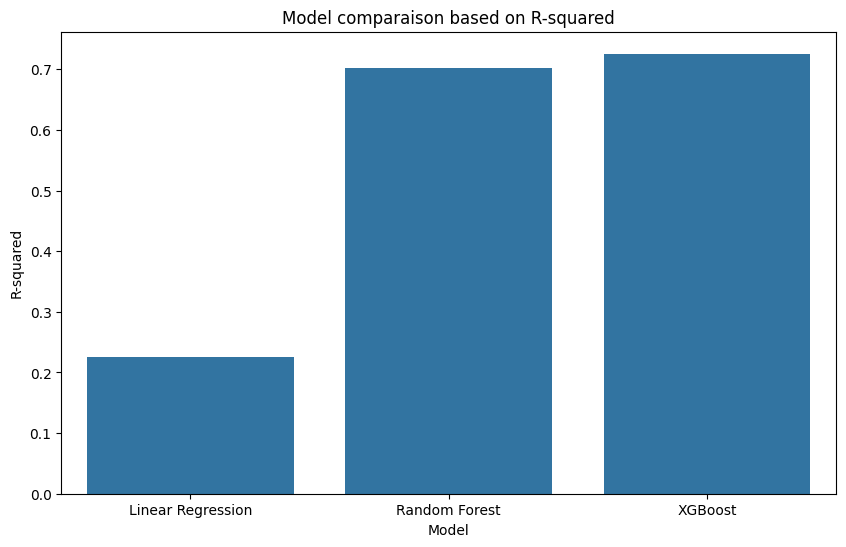

In [26]:
import matplotlib.pyplot as plt 
import seaborn as sns 

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparaison,
    x='Model',
    y='R-squared'
)

plt.title('Model comparaison based on R-squared')

plt.ylabel('R-squared')
plt.xlabel('Model')

plt.savefig(
    "../assets/model_comparison.png",
    bbox_inches="tight"
)

plt.show()

In [22]:
importance = pd.DataFrame({
    'Feature' : features,
    'Importance' : xgb.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False

)

importance



,Feature,Importance
2,pickup_longitude,0.298331
4,dropoff_longitude,0.211702
3,pickup_latitude,0.194746
5,dropoff_latitude,0.155158
6,pickup_hour,0.094614
7,pickup_month,0.035446
0,vendor_id,0.006508
1,passenger_count,0.003495


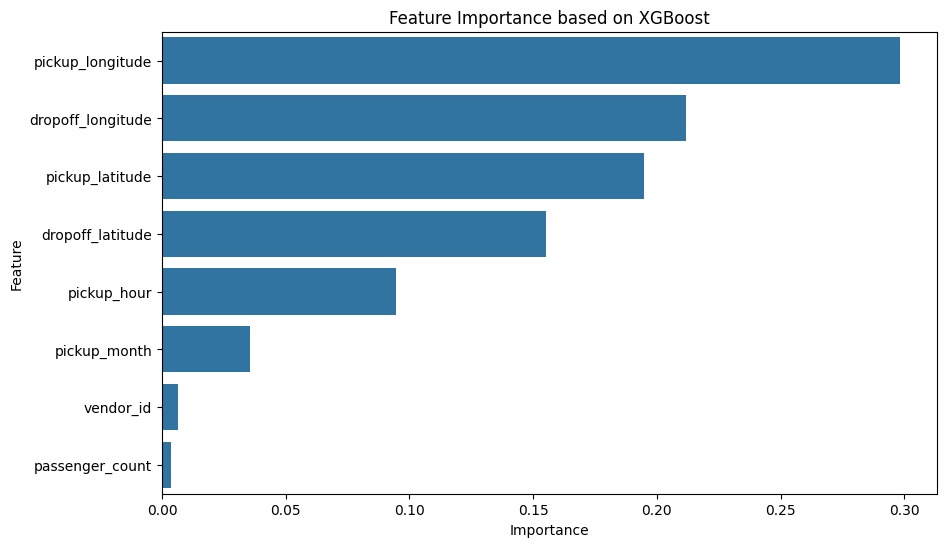

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'

)

plt.title('Feature Importance based on XGBoost')

plt.savefig(
    "../assets/feature_importance.png",
    bbox_inches="tight"
)

plt.show()

# Feature Importance Analysis

The geographic coordinates were the most influential variables for predicting trip duration.

Pickup and dropoff locations accounted for the majority of the model's predictive power.

Temporal variables such as pickup hour also contributed to the prediction process, while vendor information and passenger count had minimal impact.

These results suggest that trip duration is primarily determined by trip distance and geographic location rather than the number of passengers.

# Machine Learning Conclusion

Three predictive models were evaluated:

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

Among the evaluated models, XGBoost achieved the best predictive performance.

The final model explained approximately 73% of the variance in trip duration and significantly reduced prediction errors compared to the baseline linear regression model.

Feature importance analysis revealed that geographic coordinates were the strongest predictors of trip duration.

The model demonstrates that machine learning techniques can effectively estimate travel times using trip and location characteristics.